In [1]:
import pandas as pd
import sqlite3

In [2]:
conn = sqlite3.connect('../data/checking-logs.sqlite')

In [3]:
df = pd.read_sql("""
SELECT
    timestamp
FROM checker
WHERE uid LIKE 'user_%'
""", conn)

In [4]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['hour'] = df['timestamp'].dt.hour
df['date'] = df['timestamp'].dt.date


In [5]:
def time_period(hour):
    if 0 <= hour <= 3:
        return 'Night'
    elif 4 <= hour <= 9:
        return 'Morning'
    elif 10 <= hour <= 16:
        return 'Afternoon'
    else:
        return 'Evening'

df['period'] = df['hour'].apply(time_period)
df=df.sort_values(by='hour')
df


,timestamp,hour,date,period
366,2020-04-26 00:01:15.549361,0,2020-04-26,Night
367,2020-04-26 00:01:15.712162,0,2020-04-26,Night
2456,2020-05-14 00:00:36.334558,0,2020-05-14,Night
2457,2020-05-14 00:00:57.174472,0,2020-05-14,Night
203,2020-04-23 00:23:49.850904,0,2020-04-23,Night
...,...,...,...,...
998,2020-05-02 23:10:35.833404,23,2020-05-02,Evening
997,2020-05-02 23:10:35.718198,23,2020-05-02,Evening
996,2020-05-02 23:07:27.852183,23,2020-05-02,Evening
995,2020-05-02 23:07:27.748714,23,2020-05-02,Evening


In [6]:
grouped = (
    df
    .groupby(['date', 'period'])
    .size()
    .reset_index(name='commits')
)
grouped

,date,period,commits
0,2020-04-17,Afternoon,10
1,2020-04-17,Morning,13
2,2020-04-18,Afternoon,33
3,2020-04-18,Evening,35
4,2020-04-18,Morning,1
...,...,...,...
85,2020-05-20,Evening,10
86,2020-05-20,Morning,7
87,2020-05-21,Afternoon,27
88,2020-05-21,Evening,21


In [7]:
pivot = grouped.pivot(
    index='date',
    columns='period',
    values='commits'
).fillna(0)
pivot=pivot[['Night','Morning','Afternoon','Evening']]
pivot

period,Night,Morning,Afternoon,Evening
date,,,,
2020-04-17,0.0,13.0,10.0,0.0
2020-04-18,0.0,1.0,33.0,35.0
2020-04-19,2.0,4.0,16.0,11.0
2020-04-20,0.0,0.0,12.0,13.0
2020-04-21,0.0,0.0,0.0,25.0
2020-04-22,0.0,0.0,4.0,24.0
2020-04-23,2.0,6.0,15.0,20.0
2020-04-24,0.0,0.0,4.0,12.0
2020-04-25,1.0,21.0,33.0,49.0


[Text(0, 0, '2020-04-17'),
 Text(1, 0, '2020-04-18'),
 Text(2, 0, '2020-04-19'),
 Text(3, 0, '2020-04-20'),
 Text(4, 0, '2020-04-21'),
 Text(5, 0, '2020-04-22'),
 Text(6, 0, '2020-04-23'),
 Text(7, 0, '2020-04-24'),
 Text(8, 0, '2020-04-25'),
 Text(9, 0, '2020-04-26'),
 Text(10, 0, '2020-04-27'),
 Text(11, 0, '2020-04-28'),
 Text(12, 0, '2020-04-29'),
 Text(13, 0, '2020-04-30'),
 Text(14, 0, '2020-05-01'),
 Text(15, 0, '2020-05-02'),
 Text(16, 0, '2020-05-03'),
 Text(17, 0, '2020-05-04'),
 Text(18, 0, '2020-05-05'),
 Text(19, 0, '2020-05-06'),
 Text(20, 0, '2020-05-07'),
 Text(21, 0, '2020-05-08'),
 Text(22, 0, '2020-05-09'),
 Text(23, 0, '2020-05-10'),
 Text(24, 0, '2020-05-11'),
 Text(25, 0, '2020-05-12'),
 Text(26, 0, '2020-05-13'),
 Text(27, 0, '2020-05-14'),
 Text(28, 0, '2020-05-15'),
 Text(29, 0, '2020-05-16'),
 Text(30, 0, '2020-05-17'),
 Text(31, 0, '2020-05-18'),
 Text(32, 0, '2020-05-19'),
 Text(33, 0, '2020-05-20'),
 Text(34, 0, '2020-05-21')]

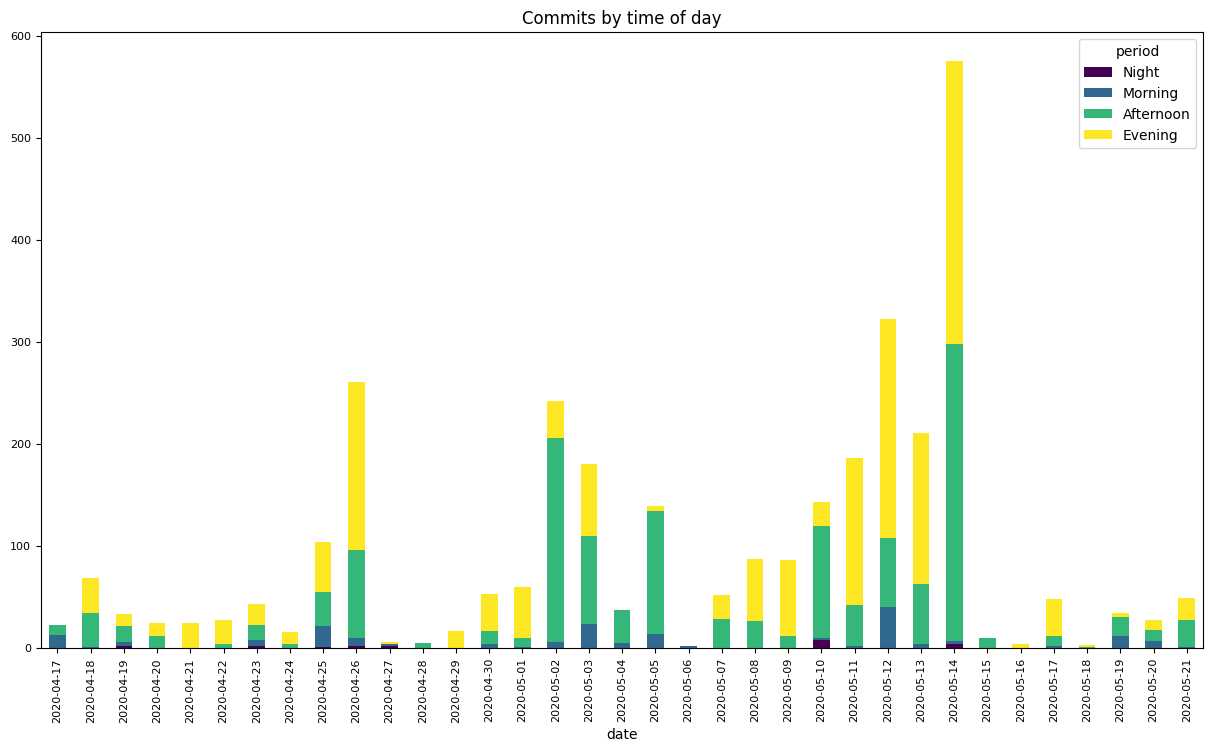

In [8]:
ax = pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 8),
    fontsize=8,
    colormap='viridis',
    title='Commits by time of day'
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


In [9]:
conn.close()

In [10]:
pivot['sum_all']=pivot['Afternoon']+pivot['Evening']+pivot['Morning']+pivot['Night']
print(pivot.loc[[pivot['sum_all'].idxmax()]])
pivot= pivot.drop(columns=['sum_all'])

period      Night  Morning  Afternoon  Evening  sum_all
date                                                   
2020-05-14    4.0      3.0      291.0    277.0    575.0


Which day has:

the most number of commits? 2020-05-14 

and at the same time, is the number of commits higher in the evening than in the afternoon? No